Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

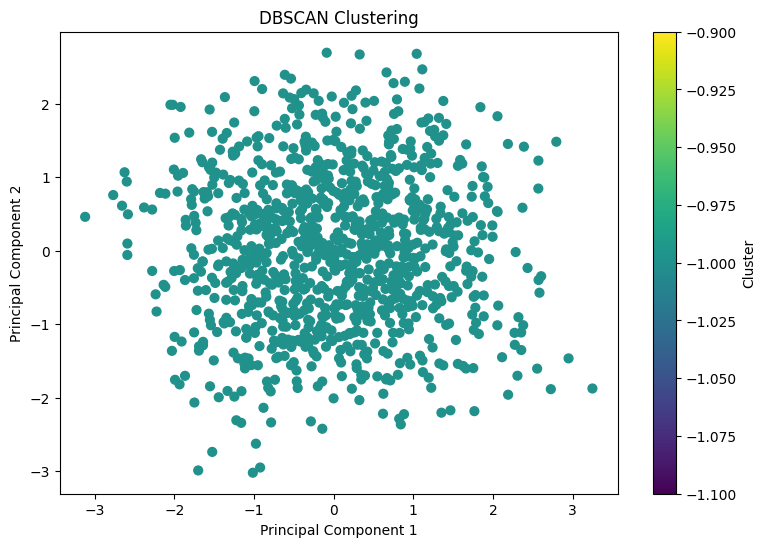

In [1]:
# EXERCISE - 14 (DBSCAN CLUSTERING)

#!/usr/bin/env python
# coding: utf-8

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

df = pd.read_csv("/content/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)

    ]
)

X_processed = preprocessor.fit_transform(X)

X_processed = X_processed

dbscan = DBSCAN(
    eps=1.5,
    min_samples=5
)

labels = dbscan.fit_predict(X_processed)

df["Cluster"] = labels

print("\nCluster Labels:")
print(df["Cluster"].value_counts().sort_index())

noise_points = df[df["Cluster"] == -1]

print("\nNumber of Noise Points:")
print(len(noise_points))

print("\nNoise Points:")
print(noise_points.head(10))

number_of_clusters = len(
    set(labels)
) - (1 if -1 in labels else 0)

print("\nNumber of Clusters:")
print(number_of_clusters)

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_processed)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="viridis",
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clustering")

plt.colorbar(label="Cluster")

plt.show()